# Project 1: Predicting Employee Attrition at Canterra

**OPAN 6603, Machine Learning II** | Pedro Sanchez and Anton van der Laan

We compare a Random Forest and a neural network to estimate attrition risk. Our practical question is how many employees who later left would have been on a list of people HR could contact for a retention conversation.

**How to run:** Put `Employee_Data_Project.xlsx` beside this notebook, or upload it when prompted in Colab. Run the cells from top to bottom. The hyperparameter searches take several minutes. Saved results were generated with Python 3.13, scikit-learn 1.9 and pandas 3.0. Other versions can change the scores slightly.

In [1]:
### Step 0: Setup ----

# Uncomment and adjust to install libraries not available on Google Colab
# !pip install packagename

# Core
import os
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd

# Visualization / EDA
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# sklearn: preprocessing + modeling
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# sklearn: model selection / evaluation
from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    classification_report,
    confusion_matrix
)
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

# global variable for random state
RANDOM_STATE = 6603

# Keep the output readable: convergence is checked explicitly in Step 5C
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore:Stochastic Optimizer:UserWarning"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [2]:
# Use consistent colors in the figures that support the report.
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#8a8985", "#262624"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f3f7fc", "#9cc2ee", BLUE, "#123f7a"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png")

In [3]:
# Colab can prompt for an upload. For local Jupyter, keep the workbook beside the notebook.
data_file = Path("Employee_Data_Project.xlsx")
if not data_file.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            "Place Employee_Data_Project.xlsx beside this notebook and run again."
        ) from None
    files.upload()

raw = pd.read_excel(data_file)
print("Rows, columns:", raw.shape)

Rows, columns: (4410, 18)


## Step 1: Pre-processing

### 1a. Structure of the data

One row per employee record, 18 columns. The outcome is `Attrition` (Yes = the employee left last year).

In [4]:
### Step 1: Pre-processing ----

# check data structure
raw.info()

raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   DistanceFromHome         4410 non-null   int64  
 4   Education                4410 non-null   int64  
 5   EmployeeID               4410 non-null   int64  
 6   Gender                   4410 non-null   str    
 7   JobLevel                 4410 non-null   int64  
 8   MaritalStatus            4410 non-null   str    
 9   Income                   4410 non-null   int64  
 10  NumCompaniesWorked       4391 non-null   float64
 11  StandardHours            4410 non-null   int64  
 12  TotalWorkingYears        4401 non-null   float64
 13  TrainingTimesLastYear    4410 non-null   int64  
 14  YearsAtCompany           4410 non-n

,Age,Attrition,BusinessTravel,DistanceFromHome,Education,EmployeeID,Gender,JobLevel,MaritalStatus,Income,NumCompaniesWorked,StandardHours,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction
0,51,No,Travel_Rarely,6,2,1,Female,1,Married,131160,1.0,8,1.0,6,1,0,3.0,4.0
1,31,Yes,Travel_Frequently,10,1,2,Female,1,Single,41890,0.0,8,6.0,3,5,4,3.0,2.0
2,32,No,Travel_Frequently,17,4,3,Male,4,Married,193280,1.0,8,5.0,2,5,3,2.0,2.0
3,38,No,Non-Travel,2,5,4,Male,3,Married,83210,3.0,8,13.0,5,8,5,4.0,4.0
4,32,No,Travel_Rarely,10,1,5,Male,1,Single,23420,4.0,8,9.0,2,6,4,4.0,1.0


In [5]:
# Basic quality checks: missing values, columns that never vary, and the outcome balance
print("Missing values by column (non-zero only):")
missing = raw.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nColumns with a single value (no information for a model):")
print([c for c in raw.columns if raw[c].nunique() == 1])

print("\nOutcome balance:")
print(raw["Attrition"].value_counts())
print("Attrition rate:", round((raw["Attrition"] == "Yes").mean(), 4))

Missing values by column (non-zero only):
EnvironmentSatisfaction    25
JobSatisfaction            20
NumCompaniesWorked         19
TotalWorkingYears           9
dtype: int64

Columns with a single value (no information for a model):
['StandardHours']

Outcome balance:
Attrition
No     3699
Yes     711
Name: count, dtype: int64
Attrition rate: 0.1612


**What this shows**

- Four columns have a few missing values (73 cells in total, under 0.6% of any column).
- `StandardHours` is 8 for everyone, so it cannot help predict anything. `EmployeeID` is only a label.
- 16.1% of records are leavers. The classes are imbalanced, so accuracy alone is a poor yardstick: a "model" that says nobody leaves is right 83.9% of the time.

### 1b. Repeated employee profiles

In [6]:
# Find repeated profiles without looking at the target or the employee ID.
profile_cols = [c for c in raw.columns if c not in ["EmployeeID", "Attrition"]]
complete_cols = [c for c in profile_cols if raw[c].notna().all()]
incomplete_cols = [c for c in profile_cols if c not in complete_cols]

raw["ProfileID"] = raw.groupby(complete_cols, sort=False).ngroup()
groups = raw.groupby("ProfileID")
print("Distinct employee profiles:", groups.ngroups)
print("Records per profile (group size: number of profiles):")
print(groups.size().value_counts().to_string())
print("Every profile has one recorded outcome:", groups["Attrition"].nunique().eq(1).all())

Distinct employee profiles: 1470
Records per profile (group size: number of profiles):
3    1470
Every profile has one recorded outcome: True


In [7]:
# Confirm that the file contains three matching blocks and that the copies agree.
n_profiles = raw["ProfileID"].nunique()
profile_ids = raw["ProfileID"].to_numpy()
matches = (
    len(raw) == 3 * n_profiles
    and np.array_equal(profile_ids[:n_profiles], profile_ids[n_profiles:2 * n_profiles])
    and np.array_equal(profile_ids[:n_profiles], profile_ids[2 * n_profiles:])
)
print("The three blocks contain the same profiles in the same order:", matches)

check_cols = incomplete_cols + ["Attrition"]
unique_values = raw.groupby("ProfileID")[check_cols].nunique()
print("\nLargest number of distinct nonblank values per profile:")
print(unique_values.max().to_string())
if not matches or not unique_values.eq(1).all().all():
    raise ValueError("The expected profile copies disagree or are incomplete. Review the input file.")

The three blocks contain the same profiles in the same order: True

Largest number of distinct nonblank values per profile:
NumCompaniesWorked         1
TotalWorkingYears          1
EnvironmentSatisfaction    1
JobSatisfaction            1
Attrition                  1


We found **1,470 profiles**, each appearing in all three blocks of the workbook under different IDs. We matched the rows using complete predictors and then checked that the outcomes and all nonblank values agreed. We treat these records as copies of the same person. HR should confirm how they were created.

Keeping all three would let copies of the same profile land in training and testing. Step 7 shows how much that can inflate the scores.

In [8]:
# Consolidate to one row per employee profile.
# .first() takes the first NON-missing value in each column, so a blank in one copy
# is filled from another copy of the same person.
employees = (
    raw.sort_values("EmployeeID")
       .groupby("ProfileID", sort=False)
       .first()
       .reset_index(drop=True)
)

print("Rows before:", len(raw), "| rows after:", len(employees))
print("Missing cells before:", int(raw[profile_cols + ["Attrition"]].isna().sum().sum()),
      "| missing cells after:", int(employees.isna().sum().sum()))
print("Attrition rate before:", round((raw["Attrition"] == "Yes").mean(), 4),
      "| after:", round((employees["Attrition"] == "Yes").mean(), 4))

Rows before: 4410 | rows after: 1470
Missing cells before: 73 | missing cells after: 0
Attrition rate before: 0.1612 | after: 0.1612


### 1c. Encoding

| Choice | Reason |
|---|---|
| `Attrition` becomes 1 (left) / 0 (stayed) | Models need a numeric outcome; 1 is the event we want the probability of. |
| Drop `StandardHours`; use `EmployeeID` only as the row label | A constant and an identifier carry no signal. |
| `BusinessTravel`, `Gender`, `MaritalStatus` become 0/1 indicator columns | They are categories with no numeric meaning. One level of each is left out as the reference (non-travel, female, married) because it is implied by the others. |
| `Education`, `JobLevel`, `EnvironmentSatisfaction`, `JobSatisfaction` stay as numbers | They are ordered scales (1 is lowest). Keeping the order lets a tree split "3 or above" and keeps the network small. |
| No rows removed for extreme values | Income up to \$200k and tenure up to 40 years are plausible for senior staff. |

In [9]:
# Outcome to 1/0, drop the constant column, use the ID as the row label
employees["Attrition"] = (employees["Attrition"] == "Yes").astype(int)
employees = employees.drop(columns=["StandardHours"]).set_index("EmployeeID")

# Indicator columns for the three nominal variables, with clearer names
model_df = pd.get_dummies(
    employees,
    columns=["BusinessTravel", "Gender", "MaritalStatus"],
    dtype=int
)
model_df = model_df.drop(columns=[
    "BusinessTravel_Non-Travel",   # reference level
    "Gender_Female",               # reference level
    "MaritalStatus_Married"        # reference level
]).rename(columns={
    "BusinessTravel_Travel_Frequently": "Travel_Frequently",
    "BusinessTravel_Travel_Rarely": "Travel_Rarely",
    "Gender_Male": "Male",
    "MaritalStatus_Single": "Single",
    "MaritalStatus_Divorced": "Divorced"
})

# check our data
model_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 1 to 1470
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      1470 non-null   int64  
 1   Attrition                1470 non-null   int64  
 2   DistanceFromHome         1470 non-null   int64  
 3   Education                1470 non-null   int64  
 4   JobLevel                 1470 non-null   int64  
 5   Income                   1470 non-null   int64  
 6   NumCompaniesWorked       1470 non-null   float64
 7   TotalWorkingYears        1470 non-null   float64
 8   TrainingTimesLastYear    1470 non-null   int64  
 9   YearsAtCompany           1470 non-null   int64  
 10  YearsWithCurrManager     1470 non-null   int64  
 11  EnvironmentSatisfaction  1470 non-null   float64
 12  JobSatisfaction          1470 non-null   float64
 13  Travel_Frequently        1470 non-null   int64  
 14  Travel_Rarely            1470 non-n

## Step 2: Split into training and test sets

70% training, 30% test, stratified so both keep the 16% attrition rate. The test set is not touched again until Step 6. Because each employee is now a single row, nobody can be in both sets.

In [10]:
### Step 2: Split data into train and test sets ----

train, test = train_test_split(
    model_df,
    test_size=0.30,
    stratify=model_df["Attrition"],
    random_state=RANDOM_STATE
)

print("Train shape:", train.shape, "| leavers:", int(train["Attrition"].sum()),
      "| attrition rate:", round(train["Attrition"].mean(), 4))
print("Test shape: ", test.shape, "| leavers:", int(test["Attrition"].sum()),
      "| attrition rate:", round(test["Attrition"].mean(), 4))

# Readable (un-encoded) version of the training rows, for charts only
train_eda = employees.loc[train.index].copy()

Train shape: (1029, 18) | leavers: 166 | attrition rate: 0.1613
Test shape:  (441, 18) | leavers: 71 | attrition rate: 0.161


## Step 3: Exploratory data analysis (training data only)

In [11]:
### Step 3: Exploratory data analysis ----

# Summarize and visualize the *training* data
train_eda.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1029.0,37.00,9.24,18.0,30.0,36.0,43.0,60.0
Attrition,1029.0,0.16,0.37,0.0,0.0,0.0,0.0,1.0
DistanceFromHome,1029.0,9.10,8.09,1.0,2.0,7.0,14.0,29.0
Education,1029.0,2.88,1.01,1.0,2.0,3.0,4.0,5.0
JobLevel,1029.0,2.05,1.08,1.0,1.0,2.0,3.0,5.0
Income,1029.0,64785.35,46285.35,10090.0,29740.0,49990.0,81890.0,199990.0
NumCompaniesWorked,1029.0,2.69,2.47,0.0,1.0,2.0,4.0,9.0
TotalWorkingYears,1029.0,11.35,7.78,0.0,6.0,10.0,15.0,40.0
TrainingTimesLastYear,1029.0,2.81,1.31,0.0,2.0,3.0,3.0,6.0
YearsAtCompany,1029.0,7.06,6.15,0.0,3.0,5.0,9.0,40.0


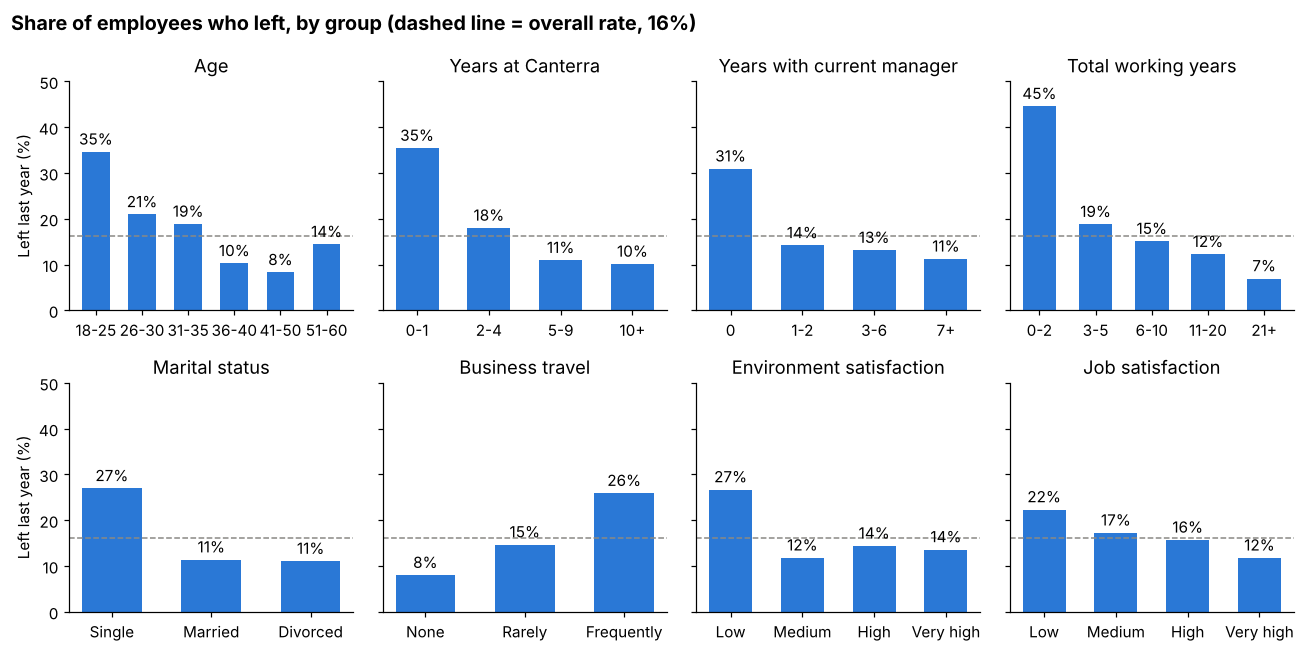

In [12]:
# Attrition rate by group, for the variables HR can most easily read.
# Each panel answers: "what share of this group left?" The dashed line is the overall rate.
base_rate = train_eda["Attrition"].mean()

def rate_panel(ax, groups, title, order=None, rotate=False):
    stats = train_eda.groupby(groups, observed=True)["Attrition"].agg(["mean", "size"])
    if order is not None:
        stats = stats.reindex(order)
    labels = [str(i) for i in stats.index]
    ax.bar(labels, stats["mean"] * 100, width=0.6, color=BLUE)
    ax.axhline(base_rate * 100, color=GRAY, linestyle="--", linewidth=1)
    for x, (rate, size) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(x, rate * 100 + 0.8, f"{rate * 100:.0f}%", ha="center", va="bottom", fontsize=10)
    ax.set_title(title)
    ax.set_ylim(0, 50)
    ax.tick_params(axis="x", labelsize=10)
    ax.grid(axis="x", visible=False)
    if rotate:
        ax.tick_params(axis="x", labelrotation=20)
    return stats

age_band = pd.cut(train_eda["Age"], [17, 25, 30, 35, 40, 50, 60],
                  labels=["18-25", "26-30", "31-35", "36-40", "41-50", "51-60"])
tenure_band = pd.cut(train_eda["YearsAtCompany"], [-1, 1, 4, 9, 40],
                     labels=["0-1", "2-4", "5-9", "10+"])
manager_band = pd.cut(train_eda["YearsWithCurrManager"], [-1, 0, 2, 6, 17],
                      labels=["0", "1-2", "3-6", "7+"])
experience_band = pd.cut(train_eda["TotalWorkingYears"], [-1, 2, 5, 10, 20, 40],
                         labels=["0-2", "3-5", "6-10", "11-20", "21+"])
companies_band = pd.cut(train_eda["NumCompaniesWorked"], [-1, 1, 4, 9],
                        labels=["0-1", "2-4", "5+"])
sat_labels = {1: "Low", 2: "Medium", 3: "High", 4: "Very high"}

fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharey=True)
rate_panel(axes[0, 0], age_band, "Age")
rate_panel(axes[0, 1], tenure_band, "Years at Canterra")
rate_panel(axes[0, 2], manager_band, "Years with current manager")
rate_panel(axes[0, 3], experience_band, "Total working years")
rate_panel(axes[1, 0], "MaritalStatus", "Marital status", order=["Single", "Married", "Divorced"])
rate_panel(axes[1, 1], train_eda["BusinessTravel"].str.replace("Travel_", "").str.replace("Non-Travel", "None"),
           "Business travel", order=["None", "Rarely", "Frequently"])
rate_panel(axes[1, 2], train_eda["EnvironmentSatisfaction"].astype(int).map(sat_labels),
           "Environment satisfaction", order=list(sat_labels.values()))
rate_panel(axes[1, 3], train_eda["JobSatisfaction"].astype(int).map(sat_labels),
           "Job satisfaction", order=list(sat_labels.values()))
for ax in axes[:, 0]:
    ax.set_ylabel("Left last year (%)")
fig.suptitle(f"Share of employees who left, by group (dashed line = overall rate, {base_rate * 100:.0f}%)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
save_fig("eda_attrition_by_group")
plt.show()

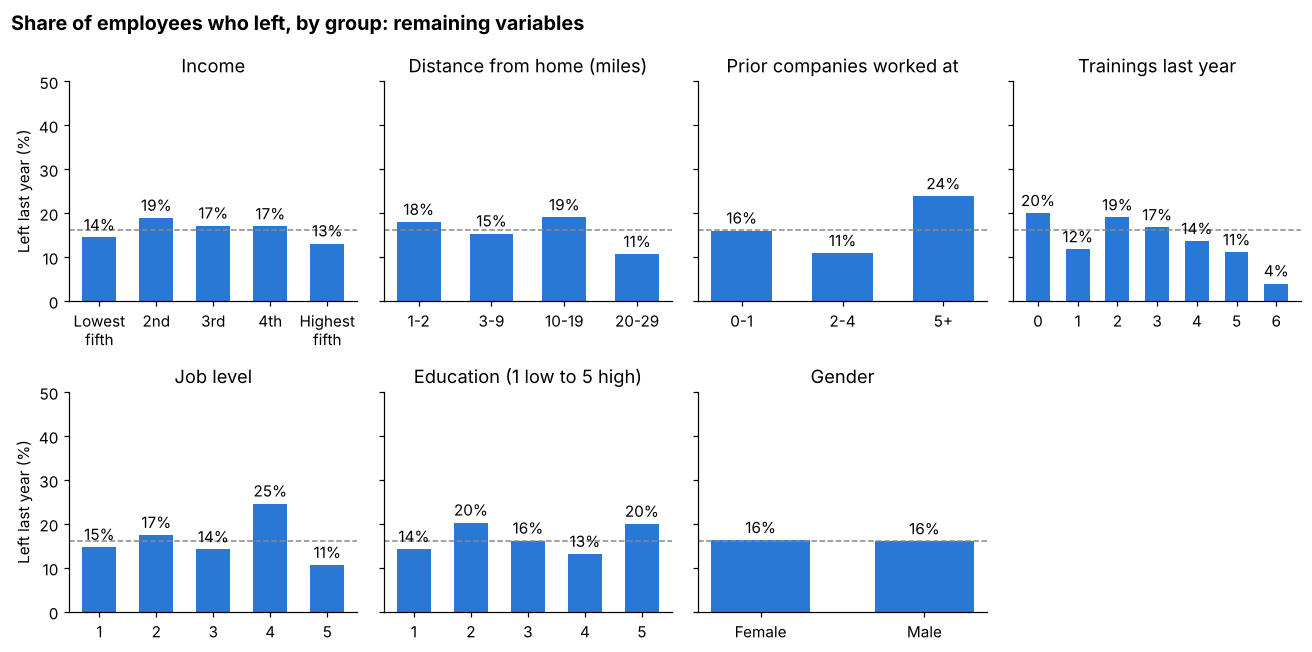

In [13]:
# The remaining variables, same view
income_band = pd.qcut(train_eda["Income"], 5, labels=["Lowest\nfifth", "2nd", "3rd", "4th", "Highest\nfifth"])
distance_band = pd.cut(train_eda["DistanceFromHome"], [0, 2, 9, 19, 29], labels=["1-2", "3-9", "10-19", "20-29"])

fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharey=True)
rate_panel(axes[0, 0], income_band, "Income")
rate_panel(axes[0, 1], distance_band, "Distance from home (miles)")
rate_panel(axes[0, 2], companies_band, "Prior companies worked at")
rate_panel(axes[0, 3], "TrainingTimesLastYear", "Trainings last year")
rate_panel(axes[1, 0], "JobLevel", "Job level")
rate_panel(axes[1, 1], "Education", "Education (1 low to 5 high)")
rate_panel(axes[1, 2], "Gender", "Gender")
axes[1, 3].axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("Left last year (%)")
fig.suptitle("Share of employees who left, by group: remaining variables",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
save_fig("eda_attrition_by_group_other")
plt.show()

In [14]:
# Time with manager overlaps with being new to Canterra.
# Split the training employees by both, to see which one the higher attrition follows.
first_year_with_manager = train_eda["YearsWithCurrManager"] == 0
recent_hire = train_eda["YearsAtCompany"] <= 1

def group_rate(mask):
    group = train_eda[mask]
    return {"employees": len(group), "left": int(group["Attrition"].sum()),
            "attrition_rate": round(group["Attrition"].mean(), 3)}

pd.DataFrame({
    "First year with manager, 0-1 years at Canterra": group_rate(first_year_with_manager & recent_hire),
    "First year with manager, 2+ years at Canterra": group_rate(first_year_with_manager & ~recent_hire),
    "Longer with manager, 0-1 years at Canterra": group_rate(~first_year_with_manager & recent_hire),
    "Longer with manager, 2+ years at Canterra": group_rate(~first_year_with_manager & ~recent_hire),
}).T

,employees,left,attrition_rate
"First year with manager, 0-1 years at Canterra",147.0,52.0,0.354
"First year with manager, 2+ years at Canterra",47.0,8.0,0.170
"Longer with manager, 0-1 years at Canterra",11.0,4.0,0.364
"Longer with manager, 2+ years at Canterra",824.0,102.0,0.124


**What stood out in the training data**

- **Early tenure:** 56 of 158 employees with 0–1 recorded years at Canterra left (35%). The rate was about 11% for employees with five years or more.
- **Time with manager:** 31% of employees with zero completed years under their current manager left. The table above shows that 147 of those 194 employees are recent hires, and they left at 35%. Among the 47 longer-serving employees in their first year with a manager, 8 left (17%), compared with 12% of other longer-serving employees. That gap rests on 47 people, so we treat it as something to watch.
- **Travel and satisfaction:** 26% of frequent travelers left, compared with 15% of occasional travelers and 8% of non-travelers. Among employees with the lowest work-environment rating, 27% left. Other ratings ranged from 12% to 14%.
- **Personal characteristics:** Younger and single employees had higher observed rates. These differences help describe the sample. For outreach, focus on work conditions and support HR can change.

## Step 4: Feature engineering and preparation for the two models

Tree splits depend on the order of values, so the Random Forest can use the original scales. The neural network standardizes the inputs to make training more stable. We include a median imputer in both pipelines. It has no work to do on this cleaned dataset. The imputer and scaler are fitted inside each training fold.

Only 16% of employees left. The Week 1 demo handled imbalance by down-sampling the majority class. We kept the observed class mix instead: the task asks for probabilities, which down-sampling would overstate, and with 166 leavers in training it would discard most of the data. We compared models using AUC and outreach recall, which do not depend on a 50% cutoff. We also tested class weights for the Random Forest, its built-in way of re-balancing, to see how they affected both ranking and probability error.

In [15]:
### Step 4: Feature engineering ----

# separate out X and y vars for the training and test sets
X_train = train.drop(columns=["Attrition"])
y_train = train["Attrition"]

X_test = test.drop(columns=["Attrition"])
y_test = test["Attrition"]

print("Number of predictors, p:", X_train.shape[1])
print(list(X_train.columns))

# Preprocessing for tree models: impute only (median; a no-op today, a safeguard later)
def tree_preprocess():
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])

# Preprocessing for the neural network (and the logistic regression benchmark): impute, then standardize
def scaled_preprocess():
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

# Cross-validation design used for every tuning decision:
# 5 folds, stratified, repeated 3 times with different shuffles (15 fits per candidate).
# With only 166 leavers in training, one 5-fold run is noisy; repeating it steadies the comparison.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

Number of predictors, p: 17
['Age', 'DistanceFromHome', 'Education', 'JobLevel', 'Income', 'NumCompaniesWorked', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsWithCurrManager', 'EnvironmentSatisfaction', 'JobSatisfaction', 'Travel_Frequently', 'Travel_Rarely', 'Male', 'Divorced', 'Single']


In [16]:
# Helper: cross-validate any model and summarize it the same way
def cv_summary(name, model, X=X_train, y=y_train):
    start = time.time()
    out = cross_validate(
        model, X, y,
        cv=cv,
        scoring={"auc": "roc_auc", "ap": "average_precision", "brier": "neg_brier_score"},
        return_train_score=True,
        n_jobs=-1
    )
    return {
        "model": name,
        "cv_auc": out["test_auc"].mean(),
        "cv_auc_sd": out["test_auc"].std(),
        "train_auc": out["train_auc"].mean(),
        "cv_avg_precision": out["test_ap"].mean(),
        "cv_brier": -out["test_brier"].mean(),
        "seconds": time.time() - start,
        "fold_auc": out["test_auc"]
    }

def show(results, drop=("fold_auc",)):
    return pd.DataFrame(results).drop(columns=list(drop)).set_index("model").round(3)

**Did we need new variables?** We tested five engineered features based on income and work history: log of income, share of career spent at Canterra, average years per employer, age when the person started working, and share of Canterra tenure under the current manager. The check below compares cross-validated AUC with and without them, using quick versions of both model types.

In [17]:
# Test engineered features with cross-validation (training data only)
def add_features(X):
    X = X.copy()
    X["LogIncome"] = np.log(X["Income"])
    X["ShareOfCareerAtCanterra"] = X["YearsAtCompany"] / (X["TotalWorkingYears"] + 1)
    X["YearsPerEmployer"] = X["TotalWorkingYears"] / (X["NumCompaniesWorked"] + 1)
    X["AgeStartedWorking"] = X["Age"] - X["TotalWorkingYears"]
    X["ShareOfTenureWithManager"] = X["YearsWithCurrManager"] / (X["YearsAtCompany"] + 1)
    return X

quick_rf = Pipeline([("preprocess", tree_preprocess()),
                     ("classifier", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))])
quick_mlp = Pipeline([("preprocess", scaled_preprocess()),
                      ("classifier", MLPClassifier(hidden_layer_sizes=(8,), alpha=1.0, max_iter=2000,
                                                   random_state=RANDOM_STATE))])

feature_test = []
for label, X_version in [("Original 17 predictors", X_train), ("Plus 5 engineered", add_features(X_train))]:
    for model_name, model in [("Random forest", quick_rf), ("Neural network", quick_mlp)]:
        r = cv_summary(model_name, model, X=X_version)
        feature_test.append({"features": label, "model": model_name,
                             "cv_auc": r["cv_auc"], "cv_auc_sd": r["cv_auc_sd"]})

pd.DataFrame(feature_test).pivot(index="model", columns="features", values="cv_auc").round(3)

features,Original 17 predictors,Plus 5 engineered
model,,
Neural network,0.719,0.723
Random forest,0.724,0.718


**Result.** The engineered features showed no consistent improvement: the network moved from 0.719 to 0.723 and the forest from 0.724 to 0.718, small shifts relative to the fold-to-fold spread of about 0.05. We keep the original 17 predictors. Fewer inputs means less to maintain and explain, and the models can already combine tenure and experience on their own.

## Step 5: Model selection

All tuning uses cross-validation on the training data, scored by AUC. The test set stays untouched until Step 6.

### 5A. Reference points

Before the two required models, three simple benchmarks tell us what "good" looks like on this data:

- **No model:** predict the overall attrition rate for everyone (AUC 0.50 by definition).
- **Logistic regression:** a benchmark that relates each predictor to the log-odds of leaving.
- **A single decision tree:** the building block of the forest.

In [18]:
### Step 5: Feature and Model selection ----

# 5A) Benchmarks
no_model = DummyClassifier(strategy="prior")

logit = Pipeline([
    ("preprocess", scaled_preprocess()),
    ("classifier", LogisticRegression(max_iter=1000))
])

single_tree = Pipeline([
    ("preprocess", tree_preprocess()),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

res_none = cv_summary("No model (base rate)", no_model)
res_logit = cv_summary("Logistic regression", logit)
res_tree = cv_summary("Single decision tree", single_tree)

show([res_none, res_logit, res_tree])

,cv_auc,cv_auc_sd,train_auc,cv_avg_precision,cv_brier,seconds
model,,,,,,
No model (base rate),0.500,0.000,0.500,0.161,0.135,0.078
Logistic regression,0.737,0.051,0.777,0.454,0.116,0.197
Single decision tree,0.580,0.054,1.000,0.204,0.246,0.160


A single tree reached an AUC of 1.00 on its training data and 0.580 in validation. Logistic regression reached 0.737 in validation.

### 5B. Random Forest

The baseline uses 300 trees and the default `max_features="sqrt"` (about four predictors per split). The out-of-bag estimate uses predictions for each row from trees that did not train on that row.

In [19]:
# 5B-1) Random Forest baseline with 300 trees
rf_default = Pipeline([
    ("preprocess", tree_preprocess()),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

res_rf_default = cv_summary("Random Forest baseline (300 trees)", rf_default)

rf_default.fit(X_train, y_train)
oob_proba = rf_default.named_steps["classifier"].oob_decision_function_[:, 1]
print("max_features:", rf_default.named_steps["classifier"].max_features)
print("Out-of-bag AUC:", round(roc_auc_score(y_train, oob_proba), 3))

show([res_tree, res_rf_default])

max_features: sqrt
Out-of-bag AUC: 0.724


,cv_auc,cv_auc_sd,train_auc,cv_avg_precision,cv_brier,seconds
model,,,,,,
Single decision tree,0.580,0.054,1.0,0.204,0.246,0.160
Random Forest baseline (300 trees),0.724,0.054,1.0,0.435,0.119,5.293


**Tuning plan.** We tune the settings in order of how much they change what a forest is:

1. **`max_features` and `min_samples_leaf` together.** `max_features` is what separates a random forest from plain bagging: fewer predictors per split means trees that look less alike, and averaging less-correlated trees removes more variance. `min_samples_leaf` controls how finely each tree can carve up the data. We test `max_features` from 1 to 17 (17 = all predictors = bagging) against leaf sizes from 1 (fully grown) to 20.
2. **`max_depth` and `class_weight`,** at the best setting from stage 1. Depth is a second way to simplify trees. Class weights make the forest pay more attention to the rare leavers.
3. **`n_estimators`.** More trees take longer to train. We look for where validation AUC levels off.

In [20]:
# Helper: draw a grid-search result as a heatmap (one measure, one-hue scale, darker = higher)
def heatmap(ax, table, title, xlabel, ylabel, fmt="{:.3f}", cmap=BLUES):
    values = table.values.astype(float)
    im = ax.imshow(values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(table.shape[1]))
    ax.set_xticklabels(table.columns)
    ax.set_yticks(range(table.shape[0]))
    ax.set_yticklabels(table.index)
    midpoint = (np.nanmin(values) + np.nanmax(values)) / 2
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, fmt.format(values[i, j]), ha="center", va="center", fontsize=10,
                    color="white" if values[i, j] > midpoint else INK)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(False)
    return im

In [21]:
# 5B-2) Stage 1: max_features x min_samples_leaf (35 candidates x 15 fits each)
rf_pipe = Pipeline([
    ("preprocess", tree_preprocess()),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))
])

rf_grid_1 = {
    "classifier__max_features": [1, 2, 3, 4, 6, 9, 17],
    "classifier__min_samples_leaf": [1, 3, 5, 10, 20]
}

start = time.time()
rf_search_1 = GridSearchCV(
    estimator=rf_pipe,
    param_grid=rf_grid_1,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1,
    refit=False
)
rf_search_1.fit(X_train, y_train)
print(f"Stage 1 finished in {time.time() - start:.0f} seconds")
print("Best params:", rf_search_1.best_params_)
print("Best CV AUC:", round(rf_search_1.best_score_, 4))

rf_cv_1 = pd.DataFrame(rf_search_1.cv_results_)
rf_cv_1[[
    "param_classifier__max_features",
    "param_classifier__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "mean_train_score"
]].sort_values("mean_test_score", ascending=False).head(8).round(4)

Stage 1 finished in 124 seconds
Best params: {'classifier__max_features': 1, 'classifier__min_samples_leaf': 3}
Best CV AUC: 0.7531


,param_classifier__max_features,param_classifier__min_samples_leaf,mean_test_score,std_test_score,mean_train_score
1,1,3,0.7531,0.0546,0.9908
2,1,5,0.7461,0.0531,0.9689
3,1,10,0.7452,0.0484,0.9199
0,1,1,0.7430,0.0527,1.0000
4,1,20,0.7421,0.0523,0.8616
5,2,1,0.7414,0.0530,1.0000
6,2,3,0.7404,0.0480,0.9932
7,2,5,0.7384,0.0549,0.9734


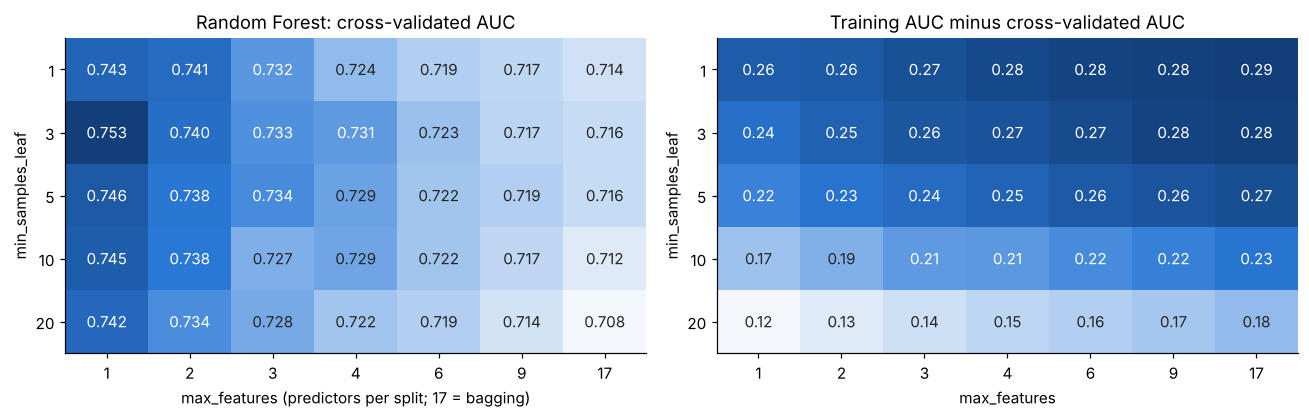

In [22]:
# Picture of stage 1: validation AUC, and how far training AUC sits above it (the overfitting gap)
rf_val = rf_cv_1.pivot(index="param_classifier__min_samples_leaf",
                       columns="param_classifier__max_features", values="mean_test_score")
rf_gap = rf_cv_1.pivot(index="param_classifier__min_samples_leaf",
                       columns="param_classifier__max_features", values="mean_train_score") - rf_val

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
heatmap(axes[0], rf_val, "Random Forest: cross-validated AUC",
        "max_features (predictors per split; 17 = bagging)", "min_samples_leaf")
heatmap(axes[1], rf_gap, "Training AUC minus cross-validated AUC",
        "max_features", "min_samples_leaf", fmt="{:.2f}")
plt.tight_layout()
save_fig("rf_tuning_heatmap")
plt.show()

**Stage 1 result.** Validation AUC was highest with one predictor per split and a minimum of three records per leaf (0.753). Trying fewer predictors at each split encourages the trees to use different variables. Larger leaves reduced the training-to-validation gap, but did not improve on the best validation score.

In [23]:
# 5B-3) Stage 2: max_depth x class_weight, holding the stage 1 winners fixed.
# Two scores this time: AUC (ranking) and the Brier score (how close the predicted
# probabilities are to what happened; lower is better).
best_max_features = rf_search_1.best_params_["classifier__max_features"]
best_min_leaf = rf_search_1.best_params_["classifier__min_samples_leaf"]

rf_pipe_2 = Pipeline([
    ("preprocess", tree_preprocess()),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_features=best_max_features,
        min_samples_leaf=best_min_leaf,
        random_state=RANDOM_STATE
    ))
])

rf_grid_2 = {
    "classifier__max_depth": [3, 5, 8, 12, None],
    "classifier__class_weight": [None, "balanced", "balanced_subsample"]
}

rf_search_2 = GridSearchCV(
    estimator=rf_pipe_2,
    param_grid=rf_grid_2,
    cv=cv,
    scoring={"auc": "roc_auc", "brier": "neg_brier_score"},
    n_jobs=-1,
    refit=False
)
rf_search_2.fit(X_train, y_train)

rf_cv_2 = pd.DataFrame(rf_search_2.cv_results_)
rf_cv_2["max_depth"] = ["None (full)" if pd.isna(v) else str(int(v))
                        for v in rf_cv_2["param_classifier__max_depth"]]
rf_cv_2["class_weight"] = ["None" if pd.isna(v) else str(v)
                           for v in rf_cv_2["param_classifier__class_weight"]]
rf_cv_2["cv_auc"] = rf_cv_2["mean_test_auc"]
rf_cv_2["cv_brier"] = -rf_cv_2["mean_test_brier"]

depth_order = ["3", "5", "8", "12", "None (full)"]
print("Cross-validated AUC (higher is better)")
print(rf_cv_2.pivot(index="max_depth", columns="class_weight", values="cv_auc").loc[depth_order].round(4).to_string())
print("\nCross-validated Brier score (lower is better)")
print(rf_cv_2.pivot(index="max_depth", columns="class_weight", values="cv_brier").loc[depth_order].round(4).to_string())

Cross-validated AUC (higher is better)
class_weight    None  balanced  balanced_subsample
max_depth                                         
3             0.7387    0.7348              0.7328
5             0.7422    0.7397              0.7313
8             0.7503    0.7419              0.7413
12            0.7505    0.7484              0.7478
None (full)   0.7531    0.7490              0.7494

Cross-validated Brier score (lower is better)
class_weight    None  balanced  balanced_subsample
max_depth                                         
3             0.1251    0.2158              0.2101
5             0.1211    0.1959              0.1828
8             0.1186    0.1728              0.1493
12            0.1180    0.1614              0.1353
None (full)   0.1180    0.1605              0.1339


**Stage 2 result.** With the stage 1 settings fixed, the best validation AUC came from trees with no depth cap and no class weights. Class weights also increased the Brier score at every depth. At full depth it rose from 0.118 to 0.134 or more, depending on the weighting option.

In [24]:
# Choose the depth and class-weight combination with the highest validation AUC.
# The Brier table above shows how the same choices affected probability error.
best_row = rf_cv_2.sort_values("cv_auc", ascending=False).iloc[0]
depth = best_row["param_classifier__max_depth"]
weight = best_row["param_classifier__class_weight"]
best_max_depth = None if pd.isna(depth) else int(depth)
best_class_weight = None if pd.isna(weight) else weight
print("Chosen max_depth:", best_max_depth, "| chosen class_weight:", best_class_weight)

Chosen max_depth: None | chosen class_weight: None


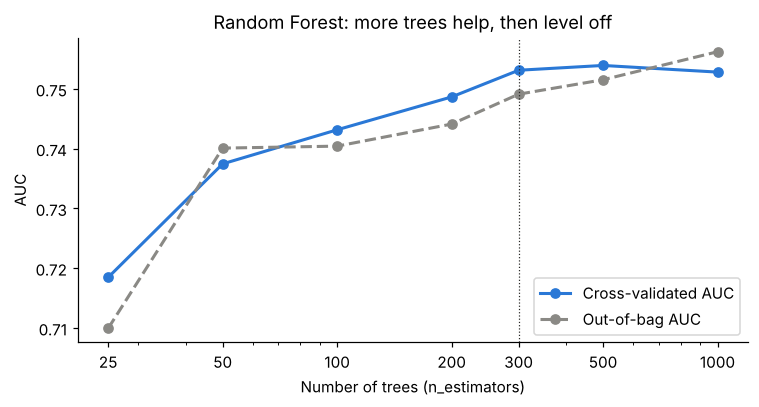

Chosen n_estimators: 300


,n_estimators,cv_auc,cv_auc_sd,oob_auc
0,25,0.7185,0.0620,0.7099
1,50,0.7375,0.0574,0.7401
2,100,0.7432,0.0514,0.7404
3,200,0.7487,0.0522,0.7441
4,300,0.7531,0.0546,0.7491
5,500,0.7539,0.0544,0.7515
6,1000,0.7528,0.0539,0.7562


In [25]:
# 5B-4) Stage 3: how many trees?
tree_counts = [25, 50, 100, 200, 300, 500, 1000]
tree_rows = []
for n_trees in tree_counts:
    candidate = Pipeline([
        ("preprocess", tree_preprocess()),
        ("classifier", RandomForestClassifier(
            n_estimators=n_trees,
            max_features=best_max_features,
            min_samples_leaf=best_min_leaf,
            max_depth=best_max_depth,
            class_weight=best_class_weight,
            oob_score=True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(candidate, X_train, y_train, cv=cv, scoring="roc_auc")["test_score"]
    candidate.fit(X_train, y_train)
    oob = roc_auc_score(y_train, candidate.named_steps["classifier"].oob_decision_function_[:, 1])
    tree_rows.append({"n_estimators": n_trees, "cv_auc": scores.mean(), "cv_auc_sd": scores.std(), "oob_auc": oob})

tree_curve = pd.DataFrame(tree_rows)

# Rule: the smallest forest within 0.002 AUC of the best one
best_n_trees = int(tree_curve.loc[tree_curve["cv_auc"] >= tree_curve["cv_auc"].max() - 0.002, "n_estimators"].min())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(tree_curve["n_estimators"], tree_curve["cv_auc"], color=BLUE, marker="o", linewidth=2, label="Cross-validated AUC")
ax.plot(tree_curve["n_estimators"], tree_curve["oob_auc"], color=GRAY, marker="o", linewidth=2, linestyle="--", label="Out-of-bag AUC")
ax.axvline(best_n_trees, color=INK, linewidth=0.8, linestyle=":")
ax.set_xscale("log")
ax.set_xticks(tree_counts)
ax.set_xticklabels(tree_counts)
ax.set_xlabel("Number of trees (n_estimators)")
ax.set_ylabel("AUC")
ax.set_title("Random Forest: more trees help, then level off")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("rf_n_estimators")
plt.show()

print("Chosen n_estimators:", best_n_trees)
tree_curve.round(4)

In [26]:
# 5B-5) The tuned Random Forest
best_rf = Pipeline([
    ("preprocess", tree_preprocess()),
    ("classifier", RandomForestClassifier(
        n_estimators=best_n_trees,
        max_features=best_max_features,
        min_samples_leaf=best_min_leaf,
        max_depth=best_max_depth,
        class_weight=best_class_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

res_rf = cv_summary("Random Forest, tuned", best_rf)

print("Final Random Forest settings:")
print({k: v for k, v in best_rf.named_steps["classifier"].get_params().items()
       if k in ["n_estimators", "max_features", "min_samples_leaf", "max_depth", "class_weight"]})

show([res_tree, res_rf_default, res_rf])

Final Random Forest settings:
{'class_weight': None, 'max_depth': None, 'max_features': 1, 'min_samples_leaf': 3, 'n_estimators': 300}


,cv_auc,cv_auc_sd,train_auc,cv_avg_precision,cv_brier,seconds
model,,,,,,
Single decision tree,0.580,0.054,1.000,0.204,0.246,0.160
Random Forest baseline (300 trees),0.724,0.054,1.000,0.435,0.119,5.293
"Random Forest, tuned",0.753,0.055,0.991,0.453,0.118,4.287


**Final Random Forest.** We used 300 trees, one predictor per split, at least three records per leaf, no depth cap, and no class weights. We chose the smallest tree count within 0.002 AUC of the best result. Validation AUC rose from 0.724 for the baseline to 0.753 for the tuned forest.

| Setting | Values tested | Chosen | Reason |
|---|---|---|---|
| `max_features` | 1, 2, 3, 4, 6, 9, 17 | 1 | Highest validation AUC; scores fell as trees were allowed more predictors per split |
| `min_samples_leaf` | 1, 3, 5, 10, 20 | 3 | Highest validation AUC; differences across leaf sizes were small |
| `max_depth` | 3, 5, 8, 12, none | none | Capping depth lowered validation AUC |
| `class_weight` | none, balanced, balanced_subsample | none | No gain in AUC, and a higher Brier score |
| `n_estimators` | 25 to 1,000 | 300 | Smallest forest within 0.002 AUC of the best |

### 5C. Artificial Neural Network

The `MLPClassifier` uses standardized inputs and a sigmoid output for the probability of attrition. The baseline starts with one hidden layer of 100 nodes, ReLU, and the default penalty of 0.0001.

In [27]:
# 5C-1) Neural network baseline (default architecture and penalty)
mlp_default = Pipeline([
    ("preprocess", scaled_preprocess()),
    ("classifier", MLPClassifier(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

res_mlp_default = cv_summary("Neural network baseline (100 nodes)", mlp_default)
show([res_logit, res_mlp_default])

,cv_auc,cv_auc_sd,train_auc,cv_avg_precision,cv_brier,seconds
model,,,,,,
Logistic regression,0.737,0.051,0.777,0.454,0.116,0.197
Neural network baseline (100 nodes),0.703,0.042,1.000,0.368,0.161,13.083


**Why tune the network?** The baseline scored 1.00 AUC in training and 0.703 in validation. That gap is a sign of overfitting.

We first compared seven network shapes and a range of L2 penalties (`alpha`). Higher penalties shrink the weights and can improve performance on new data. Then we held the best shape fixed and tested a finer range of penalties, three activation functions, two solvers, learning rate, and early stopping.

In [28]:
# 5C-2) Stage 1: architecture x L2 penalty (49 candidates x 15 fits each)
mlp_pipe = Pipeline([
    ("preprocess", scaled_preprocess()),
    ("classifier", MLPClassifier(
        random_state=RANDOM_STATE,
        max_iter=2000,
        early_stopping=False,
        solver="adam",
        activation="relu"
    ))
])

mlp_grid_1 = {
    "classifier__hidden_layer_sizes": [
        (4,),
        (8,),
        (16,),
        (32,),
        (8, 8),
        (16, 8),
        (8, 8, 8)
    ],
    "classifier__alpha": [
        1e-4,
        1e-3,
        1e-2,
        1e-1,
        1,
        3,
        10
    ]
}

start = time.time()
mlp_search_1 = GridSearchCV(
    estimator=mlp_pipe,
    param_grid=mlp_grid_1,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1,
    refit=False
)
mlp_search_1.fit(X_train, y_train)
print(f"Stage 1 finished in {time.time() - start:.0f} seconds")
print("Best params:", mlp_search_1.best_params_)
print("Best CV AUC:", round(mlp_search_1.best_score_, 4))

mlp_cv_1 = pd.DataFrame(mlp_search_1.cv_results_)
mlp_cv_1["architecture"] = mlp_cv_1["param_classifier__hidden_layer_sizes"].astype(str)
mlp_cv_1[[
    "architecture",
    "param_classifier__alpha",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "mean_fit_time"
]].sort_values("mean_test_score", ascending=False).head(8).round(4)

Stage 1 finished in 269 seconds
Best params: {'classifier__alpha': 1, 'classifier__hidden_layer_sizes': (32,)}
Best CV AUC: 0.7402


,architecture,param_classifier__alpha,mean_test_score,std_test_score,mean_train_score,mean_fit_time
31,"(32,)",1.0,0.7402,0.0477,0.8531,0.3147
38,"(32,)",3.0,0.7384,0.0527,0.7863,0.2207
39,"(8, 8)",3.0,0.7378,0.0508,0.7826,0.2565
43,"(8,)",10.0,0.7362,0.0559,0.7668,0.2507
37,"(16,)",3.0,0.7362,0.0514,0.7821,0.2593
41,"(8, 8, 8)",3.0,0.7361,0.0527,0.7826,0.3624
45,"(32,)",10.0,0.7358,0.0570,0.7641,0.1732
47,"(16, 8)",10.0,0.7357,0.0581,0.7614,0.2971


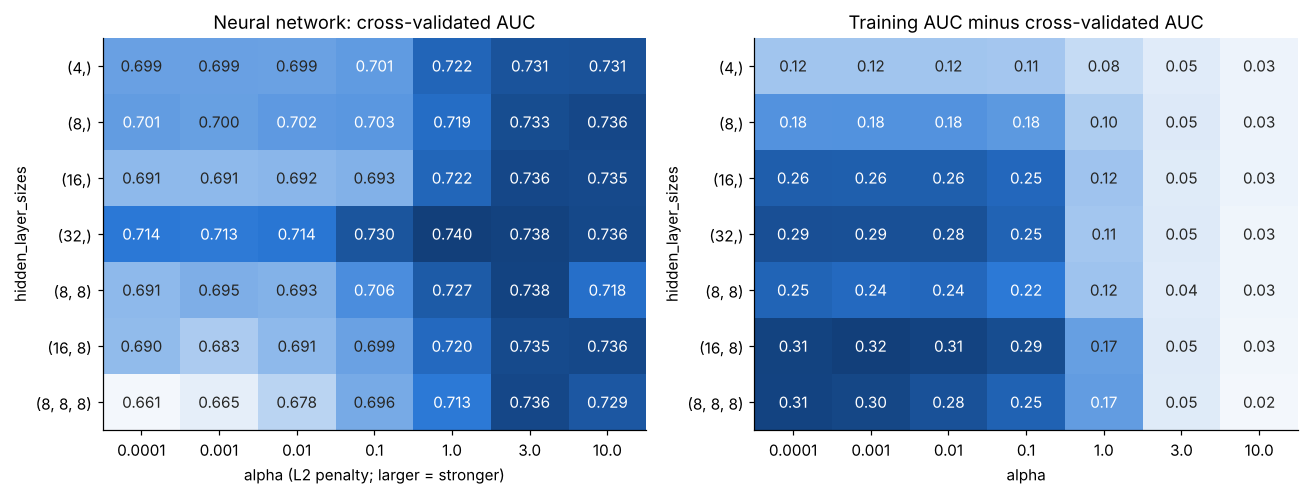

In [29]:
# Picture of stage 1
arch_order = [str(a) for a in mlp_grid_1["classifier__hidden_layer_sizes"]]
mlp_val = mlp_cv_1.pivot(index="architecture", columns="param_classifier__alpha",
                         values="mean_test_score").loc[arch_order]
mlp_gap = mlp_cv_1.pivot(index="architecture", columns="param_classifier__alpha",
                         values="mean_train_score").loc[arch_order] - mlp_val

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
heatmap(axes[0], mlp_val, "Neural network: cross-validated AUC",
        "alpha (L2 penalty; larger = stronger)", "hidden_layer_sizes")
heatmap(axes[1], mlp_gap, "Training AUC minus cross-validated AUC",
        "alpha", "hidden_layer_sizes", fmt="{:.2f}")
plt.tight_layout()
save_fig("ann_tuning_heatmap")
plt.show()

**Stage 1 result.** Higher penalties generally improved validation AUC and narrowed the gap with training. A single layer of 32 nodes with `alpha=1` scored 0.740, the best result in this grid. The three-layer network did not improve on it.

In [30]:
# 5C-3) Stage 2: training settings, at the best architecture from stage 1
best_layers = mlp_search_1.best_params_["classifier__hidden_layer_sizes"]
alpha_1 = mlp_search_1.best_params_["classifier__alpha"]
alpha_values = sorted({alpha_1 / 3, alpha_1 / 1.5, alpha_1, alpha_1 * 1.5, alpha_1 * 3})
alpha_values = [round(a, 4) for a in alpha_values]

mlp_pipe_2 = Pipeline([
    ("preprocess", scaled_preprocess()),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=best_layers,
        random_state=RANDOM_STATE,
        max_iter=2000
    ))
])

mlp_grid_2 = [
    {   # Adam: learning rate and early stopping apply
        "classifier__solver": ["adam"],
        "classifier__activation": ["relu", "tanh", "logistic"],
        "classifier__learning_rate_init": [0.001, 0.01],
        "classifier__early_stopping": [False, True],
        "classifier__alpha": alpha_values
    },
    {   # L-BFGS: no learning rate or early stopping to set
        "classifier__solver": ["lbfgs"],
        "classifier__activation": ["relu", "tanh", "logistic"],
        "classifier__alpha": alpha_values
    }
]

start = time.time()
mlp_search_2 = GridSearchCV(
    estimator=mlp_pipe_2,
    param_grid=mlp_grid_2,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1,
    refit=False
)
mlp_search_2.fit(X_train, y_train)
print(f"Stage 2 finished in {time.time() - start:.0f} seconds ({len(mlp_search_2.cv_results_['params'])} candidates)")
print("Best params:", mlp_search_2.best_params_)
print("Best CV AUC:", round(mlp_search_2.best_score_, 4))

mlp_cv_2 = pd.DataFrame(mlp_search_2.cv_results_)
stage2_cols = ["param_classifier__solver", "param_classifier__activation", "param_classifier__learning_rate_init",
               "param_classifier__early_stopping", "param_classifier__alpha",
               "mean_test_score", "std_test_score", "mean_train_score"]
mlp_cv_2[stage2_cols].sort_values("mean_test_score", ascending=False).head(10).round(4)

Stage 2 finished in 96 seconds (75 candidates)
Best params: {'classifier__activation': 'relu', 'classifier__alpha': 1.5, 'classifier__early_stopping': False, 'classifier__learning_rate_init': 0.001, 'classifier__solver': 'adam'}
Best CV AUC: 0.7427


,param_classifier__solver,param_classifier__activation,param_classifier__learning_rate_init,param_classifier__early_stopping,param_classifier__alpha,mean_test_score,std_test_score,mean_train_score
12,adam,relu,0.001,False,1.5000,0.7427,0.0494,0.8241
11,adam,relu,0.010,True,1.0000,0.7424,0.0517,0.8215
28,adam,tanh,0.001,False,1.0000,0.7418,0.0523,0.7896
24,adam,tanh,0.001,False,0.6667,0.7415,0.0536,0.8005
32,adam,tanh,0.001,False,1.5000,0.7405,0.0516,0.7813
33,adam,tanh,0.010,False,1.5000,0.7404,0.0517,0.7732
8,adam,relu,0.001,False,1.0000,0.7402,0.0477,0.8531
15,adam,relu,0.010,True,1.5000,0.7399,0.0504,0.8121
74,lbfgs,logistic,NaN,NaN,3.0000,0.7397,0.0476,0.7970
7,adam,relu,0.010,True,0.6667,0.7396,0.0505,0.8297


In [31]:
# What each training setting does on its own: the best AUC reached with each value,
# and the average over every candidate that used it
def setting_effect(column):
    return mlp_cv_2.groupby(column, dropna=False)["mean_test_score"].agg(best="max", average="mean").round(4)

for column in ["param_classifier__solver", "param_classifier__activation",
               "param_classifier__learning_rate_init", "param_classifier__early_stopping",
               "param_classifier__alpha"]:
    print(setting_effect(column).to_string(), "\n")

                            best  average
param_classifier__solver                 
adam                      0.7427   0.6978
lbfgs                     0.7397   0.6995 

                                best  average
param_classifier__activation                 
logistic                      0.7397   0.6774
relu                          0.7427   0.7008
tanh                          0.7418   0.7161 

                                        best  average
param_classifier__learning_rate_init                 
0.001                                 0.7427   0.6689
0.010                                 0.7424   0.7266
NaN                                   0.7397   0.6995 

                                    best  average
param_classifier__early_stopping                 
False                             0.7427   0.7335
True                              0.7424   0.6620
NaN                               0.7397   0.6995 

                           best  average
param_classifier__alpha          

**Stage 2 result.** The best setting was one layer of 32 nodes, ReLU, Adam, a learning rate of 0.001, and `alpha=1.5`. Its validation AUC was 0.743. The best candidate using early stopping was close (0.742), but on average those candidates performed worse. Several settings had similar validation scores.

In [32]:
# 5C-4) The tuned neural network
best_mlp_params = {k.replace("classifier__", ""): v for k, v in mlp_search_2.best_params_.items()}

def make_ann(seed=RANDOM_STATE):
    return Pipeline([
        ("preprocess", scaled_preprocess()),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=best_layers,
            max_iter=2000,
            random_state=seed,
            **best_mlp_params
        ))
    ])

best_ann = make_ann()
res_ann = cv_summary("Neural network, tuned", best_ann)

print("Final neural network settings:")
print({"hidden_layer_sizes": best_layers, **best_mlp_params})

show([res_logit, res_mlp_default, res_ann])

Final neural network settings:
{'hidden_layer_sizes': (32,), 'activation': 'relu', 'alpha': 1.5, 'early_stopping': False, 'learning_rate_init': 0.001, 'solver': 'adam'}


,cv_auc,cv_auc_sd,train_auc,cv_avg_precision,cv_brier,seconds
model,,,,,,
Logistic regression,0.737,0.051,0.777,0.454,0.116,0.197
Neural network baseline (100 nodes),0.703,0.042,1.000,0.368,0.161,13.083
"Neural network, tuned",0.743,0.049,0.824,0.478,0.114,1.852


Iterations run: 218 of a maximum of 2000
Output activation: logistic
W0.shape = (17, 32)
W1.shape = (32, 1)
b0.shape = (32,)
b1.shape = (1,)
Total parameters (weights and biases): 609


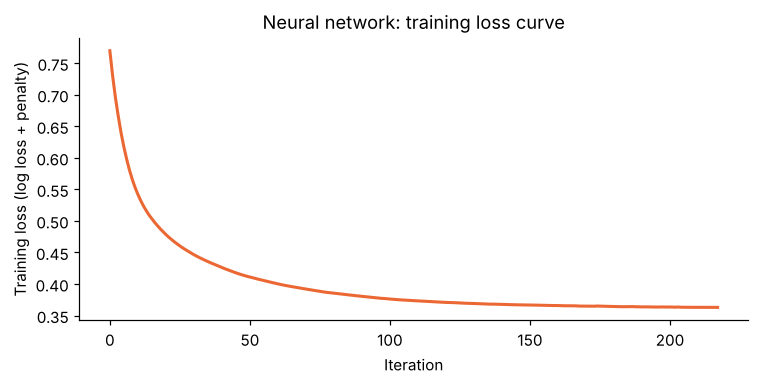

In [33]:
# Fit on the full training set and look inside: convergence, loss curve, and network size
best_ann.fit(X_train, y_train)
mlp = best_ann.named_steps["classifier"]

print("Iterations run:", mlp.n_iter_, "of a maximum of", mlp.max_iter)
print("Output activation:", mlp.out_activation_)

# Sizes of each layer
for i, W in enumerate(mlp.coefs_):
    print(f"W{i}.shape = {W.shape}")
for i, b in enumerate(mlp.intercepts_):
    print(f"b{i}.shape = {b.shape}")
n_parameters = sum(W.size for W in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print("Total parameters (weights and biases):", n_parameters)

if hasattr(mlp, "loss_curve_"):
    plt.figure(figsize=(7, 3.6))
    plt.plot(mlp.loss_curve_, color=ORANGE, linewidth=2)
    plt.xlabel("Iteration")
    plt.ylabel("Training loss (log loss + penalty)")
    plt.title("Neural network: training loss curve")
    plt.tight_layout()
    save_fig("ann_loss_curve")
    plt.show()

Tuning increased validation AUC from 0.703 to 0.743. It also reduced the training-to-validation gap from about 0.30 to 0.08. The final network has 609 parameters, including weights and biases. The loss curve above shows how training progressed.

| Setting | Values tested | Chosen | Reason |
|---|---|---|---|
| `hidden_layer_sizes` | (4,), (8,), (16,), (32,), (8, 8), (16, 8), (8, 8, 8) | (32,) | Highest validation AUC; extra layers did not help |
| `alpha` | 0.0001 to 10, then 0.33 to 3 | 1.5 | Highest validation AUC; low penalties overfit |
| `activation` | relu, tanh, logistic | relu | Best scores within 0.003 of each other |
| `solver` | adam, lbfgs | adam | Best scores within 0.003 of each other |
| `learning_rate_init` | 0.001, 0.01 | 0.001 | Same best score |
| `early_stopping` | off, on | off | No gain at best; worse on average |

### 5D. Comparing the two tuned models

All models use the same 15 train/validation splits.

In [34]:
# 5D-1) Side-by-side cross-validation results
cv_table = show([res_none, res_logit, res_tree, res_rf_default, res_rf, res_mlp_default, res_ann])
cv_table

,cv_auc,cv_auc_sd,train_auc,cv_avg_precision,cv_brier,seconds
model,,,,,,
No model (base rate),0.500,0.000,0.500,0.161,0.135,0.078
Logistic regression,0.737,0.051,0.777,0.454,0.116,0.197
Single decision tree,0.580,0.054,1.000,0.204,0.246,0.160
Random Forest baseline (300 trees),0.724,0.054,1.000,0.435,0.119,5.293
"Random Forest, tuned",0.753,0.055,0.991,0.453,0.118,4.287
Neural network baseline (100 nodes),0.703,0.042,1.000,0.368,0.161,13.083
"Neural network, tuned",0.743,0.049,0.824,0.478,0.114,1.852


**Validation results.** The tuned forest averaged 0.753 AUC, the tuned neural network 0.743, and logistic regression 0.737. We use the held-out test set to see how they compare on employees kept out of tuning.

**Outreach scenario.** We assume HR can contact 20% of employees in a pilot. Ranking by predicted risk gives each model the same number of outreach slots. We also show what happens with lists of 10%, 30%, and 40%.

## Step 6: Predictions and final model evaluation (test set)

Both tuned models are refit on all 1,029 training employees and scored once on the 441 test employees they have never seen.

**Metrics, in plain terms**

- **AUC:** how well the model ranks leavers above stayers across the full list. 0.50 is a coin flip, 1.00 is perfect.
- **Average precision:** summarizes precision across levels of recall; the no-skill value equals the attrition rate (0.16).
- **Brier score:** average squared gap between predicted probability and what happened (lower is better). Predicting 16% for everyone scores about 0.135.
- **In the riskiest 20%:** *precision* is the share of flagged employees who really left; *recall* is the share of all leavers who were on the list; *lift* is precision divided by the overall attrition rate (1.0 = no better than picking names at random).

In [35]:
### Step 6: Predictions and final model evaluation ----

# Refit on the full training set, then predict the test set
final_models = {"Random Forest": best_rf, "Neural Network": best_ann, "Logistic regression": logit}
test_proba = {}
for name, model in final_models.items():
    model.fit(X_train, y_train)
    test_proba[name] = model.predict_proba(X_test)[:, 1]

y_test_array = y_test.to_numpy()
test_rate = y_test_array.mean()
n_test = len(y_test_array)

FLAG_SHARE = 0.20

def flag_top(p, share=FLAG_SHARE):
    # True for the riskiest `share` of employees, by rank
    k = int(round(share * len(p)))
    flags = np.zeros(len(p), dtype=bool)
    flags[np.argsort(-p, kind="stable")[:k]] = True
    return flags

def test_metrics(name):
    p = test_proba[name]
    flagged = flag_top(p)
    return {
        "model": name,
        "test_auc": roc_auc_score(y_test_array, p),
        "avg_precision": average_precision_score(y_test_array, p),
        "brier": brier_score_loss(y_test_array, p),
        "accuracy_at_0.5": accuracy_score(y_test_array, p >= 0.5),
        "recall_at_0.5": recall_score(y_test_array, p >= 0.5),
        "top20_precision": precision_score(y_test_array, flagged),
        "top20_recall": recall_score(y_test_array, flagged),
        "top20_f1": f1_score(y_test_array, flagged),
        "top20_lift": precision_score(y_test_array, flagged) / test_rate
    }

test_table = pd.DataFrame([test_metrics(name) for name in final_models]).set_index("model")
print("Test employees:", len(y_test_array), "| leavers:", int(y_test_array.sum()),
      "| attrition rate:", round(test_rate, 3))
print("Accuracy from predicting 'stays' for everyone:", round(1 - test_rate, 3))
print("Brier score from predicting the base rate for everyone:",
      round(brier_score_loss(y_test_array, np.full(len(y_test_array), y_train.mean())), 3))
test_table.round(3)

Test employees: 441 | leavers: 71 | attrition rate: 0.161
Accuracy from predicting 'stays' for everyone: 0.839
Brier score from predicting the base rate for everyone: 0.135


,test_auc,avg_precision,brier,accuracy_at_0.5,recall_at_0.5,top20_precision,top20_recall,top20_f1,top20_lift
model,,,,,,,,,
Random Forest,0.671,0.385,0.124,0.844,0.028,0.330,0.408,0.365,2.047
Neural Network,0.698,0.331,0.127,0.830,0.099,0.318,0.394,0.352,1.976
Logistic regression,0.696,0.320,0.129,0.823,0.085,0.295,0.366,0.327,1.835


In [36]:
# How sure can we be? Bootstrap the test set (2,000 resamples) for a 95% interval on each AUC
# and on the Random Forest minus Neural Network difference.
rng = np.random.default_rng(RANDOM_STATE)
boot = {name: [] for name in final_models}
for _ in range(2000):
    idx = rng.integers(0, n_test, n_test)
    if y_test_array[idx].min() == y_test_array[idx].max():
        continue
    for name in final_models:
        boot[name].append(roc_auc_score(y_test_array[idx], test_proba[name][idx]))
boot = {name: np.array(values) for name, values in boot.items()}

for name in final_models:
    low, high = np.percentile(boot[name], [2.5, 97.5])
    print(f"{name:20s} test AUC {roc_auc_score(y_test_array, test_proba[name]):.3f}   95% interval {low:.3f} to {high:.3f}")

auc_diff = boot["Random Forest"] - boot["Neural Network"]
low, high = np.percentile(auc_diff, [2.5, 97.5])
print(f"\nRandom Forest minus Neural Network: {auc_diff.mean():+.3f}   95% interval {low:+.3f} to {high:+.3f}")
print("Share of resamples where the Random Forest is ahead:", round(float((auc_diff > 0).mean()), 2))

Random Forest        test AUC 0.671   95% interval 0.597 to 0.742
Neural Network       test AUC 0.698   95% interval 0.627 to 0.763
Logistic regression  test AUC 0.696   95% interval 0.627 to 0.760

Random Forest minus Neural Network: -0.027   95% interval -0.078 to +0.022
Share of resamples where the Random Forest is ahead: 0.15


In [37]:
# Classification reports and confusion matrices when the riskiest 20% are flagged
# Confusion matrix layout: rows = actual (stayed, left), columns = predicted (not flagged, flagged)
for name in ["Random Forest", "Neural Network"]:
    predicted = flag_top(test_proba[name]).astype(int)
    print(f"{name}: riskiest 20% flagged ({predicted.sum()} of {len(predicted)} employees)")
    print(classification_report(y_test_array, predicted, target_names=["Stayed", "Left"], digits=3))
    print(confusion_matrix(y_test_array, predicted), "\n")

# The same question at other list sizes
depth_rows = []
for share in [0.10, 0.20, 0.30, 0.40]:
    for name in final_models:
        flagged = flag_top(test_proba[name], share)
        depth_rows.append({"list_size": f"Riskiest {share:.0%}", "model": name,
                           "employees": int(flagged.sum()), "leavers_on_list": int(y_test_array[flagged].sum()),
                           "precision": y_test_array[flagged].mean(),
                           "recall": y_test_array[flagged].sum() / y_test_array.sum(),
                           "lift": y_test_array[flagged].mean() / test_rate})
pd.DataFrame(depth_rows).set_index(["list_size", "model"]).round(3)

Random Forest: riskiest 20% flagged (88 of 441 employees)
              precision    recall  f1-score   support

      Stayed      0.881     0.841     0.860       370
        Left      0.330     0.408     0.365        71

    accuracy                          0.771       441
   macro avg      0.605     0.624     0.613       441
weighted avg      0.792     0.771     0.781       441

[[311  59]
 [ 42  29]] 

Neural Network: riskiest 20% flagged (88 of 441 employees)
              precision    recall  f1-score   support

      Stayed      0.878     0.838     0.858       370
        Left      0.318     0.394     0.352        71

    accuracy                          0.766       441
   macro avg      0.598     0.616     0.605       441
weighted avg      0.788     0.766     0.776       441

[[310  60]
 [ 43  28]] 



employees  leavers_on_list  precision  recall   lift
list_size    model                                                                    
Riskiest 10% Random Forest               44               20      0.455   0.282  2.823
             Neural Network              44               15      0.341   0.211  2.117
             Logistic regression         44               15      0.341   0.211  2.117
Riskiest 20% Random Forest               88               29      0.330   0.408  2.047
             Neural Network              88               28      0.318   0.394  1.976
             Logistic regression         88               26      0.295   0.366  1.835
Riskiest 30% Random Forest              132               37      0.280   0.521  1.741
             Neural Network             132               41      0.311   0.577  1.929
             Logistic regression        132               35      0.265   0.493  1.647
Riskiest 40% Random Forest              176               42      0.239   0.592  1.482
             Neural Network             176               47      0.267   0.662  1.659
             Logistic regression        176               47      0.267   0.662  1.659

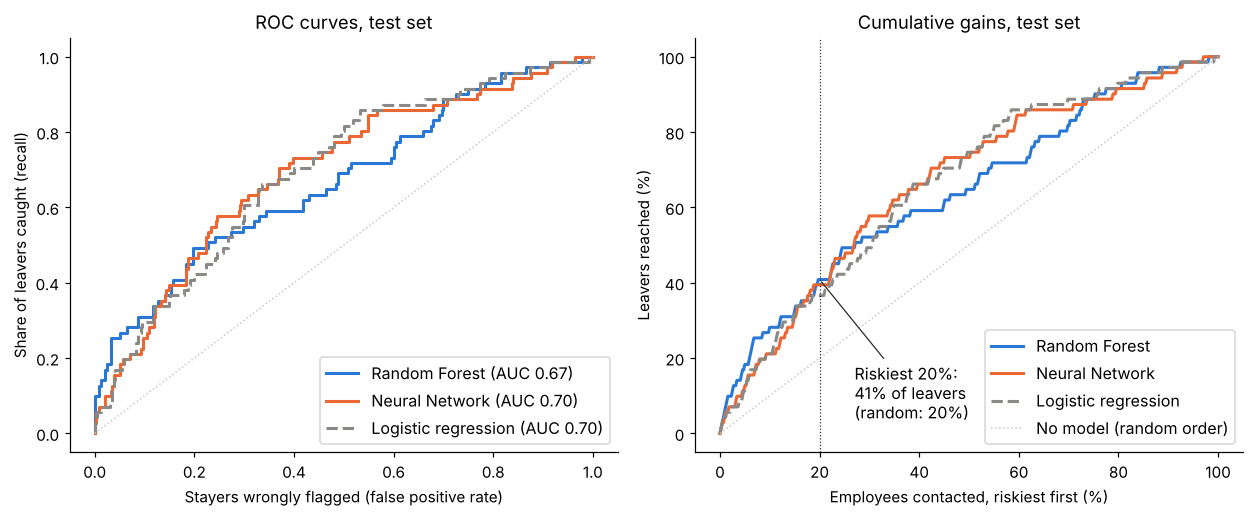

In [38]:
# ROC curves, and the "gains" view HR will actually use:
# if we contact the riskiest X% of employees, what share of all leavers do we reach?
def gains_curve(y_true, p):
    order = np.argsort(-p, kind="stable")
    captured = np.cumsum(y_true[order]) / y_true.sum()
    contacted = np.arange(1, len(y_true) + 1) / len(y_true)
    return np.insert(contacted, 0, 0), np.insert(captured, 0, 0)

series = [("Random Forest", BLUE, "-"), ("Neural Network", ORANGE, "-"), ("Logistic regression", GRAY, "--")]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

for name, color, style in series:
    fpr, tpr, _ = roc_curve(y_test_array, test_proba[name])
    axes[0].plot(fpr, tpr, color=color, linestyle=style, linewidth=2,
                 label=f"{name} (AUC {roc_auc_score(y_test_array, test_proba[name]):.2f})")
axes[0].plot([0, 1], [0, 1], color="#c9c8c2", linewidth=1, linestyle=":")
axes[0].set_xlabel("Stayers wrongly flagged (false positive rate)")
axes[0].set_ylabel("Share of leavers caught (recall)")
axes[0].set_title("ROC curves, test set")
axes[0].legend(loc="lower right", fontsize=10.5)

for name, color, style in series:
    contacted, captured = gains_curve(y_test_array, test_proba[name])
    axes[1].plot(contacted * 100, captured * 100, color=color, linestyle=style, linewidth=2, label=name)
axes[1].plot([0, 100], [0, 100], color="#c9c8c2", linewidth=1, linestyle=":", label="No model (random order)")
axes[1].axvline(20, color=INK, linewidth=0.8, linestyle=":")
contacted, captured = gains_curve(y_test_array, test_proba["Random Forest"])
rf_at_20 = captured[int(round(0.20 * n_test))] * 100
axes[1].annotate(f"Riskiest 20%:\n{rf_at_20:.0f}% of leavers\n(random: 20%)", xy=(20, rf_at_20), xytext=(27, 4),
                 fontsize=10.5, arrowprops=dict(arrowstyle="-", color=INK, linewidth=0.8))
axes[1].set_xlabel("Employees contacted, riskiest first (%)")
axes[1].set_ylabel("Leavers reached (%)")
axes[1].set_title("Cumulative gains, test set")
axes[1].legend(loc="lower right", fontsize=10.5)
plt.tight_layout()
save_fig("test_roc_gains")
plt.show()

In [39]:
# Risk tiers: sort test employees by Random Forest risk score, cut into five equal groups,
# and compare what actually happened in each.
def risk_tiers(name):
    tiers = pd.DataFrame({"risk": test_proba[name], "left": y_test_array})
    tiers["tier"] = pd.qcut(tiers["risk"].rank(method="first"), 5,
                            labels=["5 (lowest risk)", "4", "3", "2", "1 (highest risk)"])
    out = tiers.groupby("tier", observed=True).agg(
        employees=("left", "size"),
        leavers=("left", "sum"),
        avg_predicted_risk=("risk", "mean"),
        actual_attrition=("left", "mean")
    ).iloc[::-1]
    out["share_of_all_leavers"] = out["leavers"] / out["leavers"].sum()
    return out

for name in ["Random Forest", "Neural Network"]:
    print(name)
    print(risk_tiers(name).round(3).to_string(), "\n")

Random Forest
                  employees  leavers  avg_predicted_risk  actual_attrition  share_of_all_leavers
tier                                                                                            
1 (highest risk)         88       29               0.310             0.330                 0.408
2                        88       13               0.192             0.148                 0.183
3                        88        9               0.143             0.102                 0.127
4                        88       14               0.107             0.159                 0.197
5 (lowest risk)          89        6               0.070             0.067                 0.085 

Neural Network
                  employees  leavers  avg_predicted_risk  actual_attrition  share_of_all_leavers
tier                                                                                            
1 (highest risk)         88       28               0.399             0.318                 0.394

**Test results.** The neural network had the higher test AUC (0.698 vs. 0.671). The paired interval for the AUC difference includes zero, so the data leave the overall ranking advantage uncertain. Logistic regression was close at 0.696.

At the assumed outreach capacity, the forest identified 29 of 71 leavers and the neural network 28. A random list of the same size would reach about 14. The forest's top risk group averaged 31% predicted risk and 33% observed attrition. The network's top group averaged 40% predicted risk and 32% observed attrition. The forest also had the lower Brier score on this test set (0.124 vs. 0.127).

### Which predictors matter?

We look at importance two ways. The forest's built-in importance (first chart, as in the Week 1 demo) adds up how much each predictor reduced impurity across all of its splits. Permutation importance (second chart, as in the Week 2 example) works for both models: it measures how much test AUC drops when one predictor is shuffled. Importance shows which predictors a model relies on. It does not show the size or direction of their effect. Related predictors can share the same information, so a small drop alone tells us little about whether a factor matters for retention.

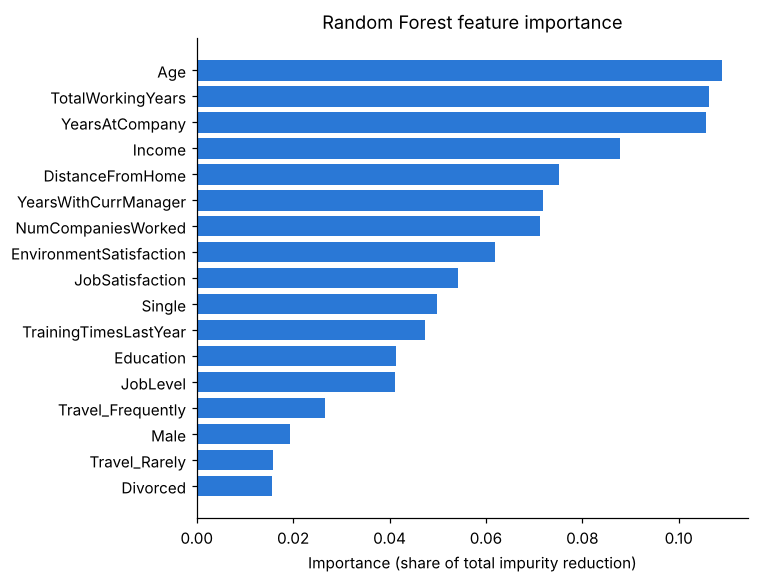

Age                        0.109
TotalWorkingYears          0.106
YearsAtCompany             0.106
Income                     0.088
DistanceFromHome           0.075
YearsWithCurrManager       0.072
NumCompaniesWorked         0.071
EnvironmentSatisfaction    0.062
JobSatisfaction            0.054
Single                     0.050
TrainingTimesLastYear      0.047
Education                  0.041
JobLevel                   0.041
Travel_Frequently          0.027
Male                       0.019
Travel_Rarely              0.016
Divorced                   0.016
dtype: float64

In [40]:
# Random Forest built-in feature importance
rf_model = best_rf.named_steps["classifier"]
rf_importance = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(7, 5.4))
plt.barh(rf_importance.index, rf_importance.values, color=BLUE)
plt.title("Random Forest feature importance")
plt.xlabel("Importance (share of total impurity reduction)")
plt.tight_layout()
save_fig("rf_feature_importance")
plt.show()

rf_importance.sort_values(ascending=False).round(3)

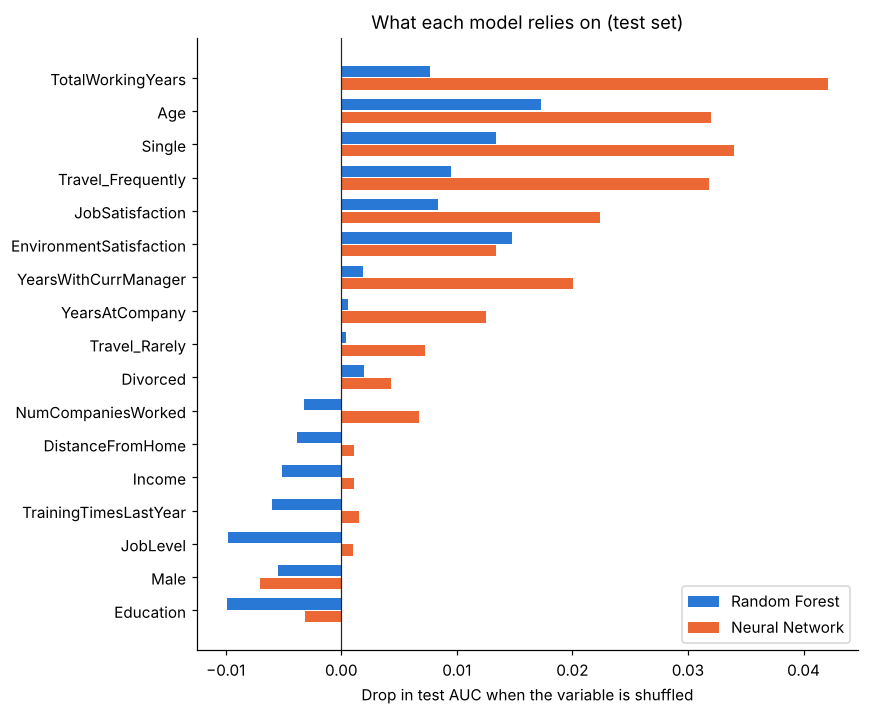

,Random Forest,Random Forest sd,Neural Network,Neural Network sd,average
TotalWorkingYears,0.0077,0.0096,0.0421,0.0193,0.0249
Age,0.0173,0.0110,0.0320,0.0127,0.0247
Single,0.0134,0.0117,0.0340,0.0147,0.0237
Travel_Frequently,0.0095,0.0094,0.0318,0.0146,0.0207
JobSatisfaction,0.0084,0.0096,0.0224,0.0115,0.0154
EnvironmentSatisfaction,0.0148,0.0100,0.0134,0.0067,0.0141
YearsWithCurrManager,0.0019,0.0063,0.0200,0.0109,0.0110
YearsAtCompany,0.0006,0.0151,0.0125,0.0044,0.0066
Travel_Rarely,0.0004,0.0059,0.0073,0.0052,0.0038
Divorced,0.0020,0.0048,0.0043,0.0032,0.0032


In [41]:
# Permutation importance on the test set for both models (drop in AUC when a variable is shuffled)
perm = {}
for name in ["Random Forest", "Neural Network"]:
    result = permutation_importance(
        final_models[name], X_test, y_test,   # test set, per the scikit-learn documentation
        n_repeats=30,
        random_state=RANDOM_STATE,
        scoring="roc_auc",
        n_jobs=-1
    )
    perm[name] = pd.Series(result.importances_mean, index=X_train.columns)
    perm[name + " sd"] = pd.Series(result.importances_std, index=X_train.columns)

perm_table = pd.DataFrame(perm)
perm_table["average"] = perm_table[["Random Forest", "Neural Network"]].mean(axis=1)
perm_table = perm_table.sort_values("average", ascending=False)

plot_table = perm_table.iloc[::-1]
positions = np.arange(len(plot_table))
fig, ax = plt.subplots(figsize=(8, 6.6))
ax.barh(positions + 0.19, plot_table["Random Forest"], height=0.34, color=BLUE, label="Random Forest")
ax.barh(positions - 0.19, plot_table["Neural Network"], height=0.34, color=ORANGE, label="Neural Network")
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_yticks(positions)
ax.set_yticklabels(plot_table.index)
ax.set_xlabel("Drop in test AUC when the variable is shuffled")
ax.set_title("What each model relies on (test set)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("permutation_importance")
plt.show()

perm_table.round(4)

**Comparing the two charts.** The forest's built-in measure puts income and distance from home in its top five and gives little weight to marital status and frequent travel. The permutation results point the other way: shuffling income or distance does not lower test AUC, while being single and traveling frequently are among the predictors both models rely on most. Built-in importance reflects how often and how usefully a predictor is split on, which favors predictors with many distinct values over yes/no indicators. We rely on the permutation results.

**What to investigate.** Age, experience, marital status, travel, and satisfaction contributed to the models' predictions. The training data also point to higher attrition among recent hires, frequent travelers, and people who reported low work-environment satisfaction. These are sensible groups or work conditions to investigate in a retention pilot. The observed differences do not establish the effect of changing travel, onboarding, or satisfaction.

### What this could mean at Canterra's scale

If Canterra has 4,000 employees and 15% annual attrition, and the test results carry over, a top-20% outreach list would contain about 245 of 600 expected departures with the forest. An equally sized random list would contain about 120. These numbers estimate who could be reached. The effect of outreach on actual departures would need to be measured in a pilot.

In [42]:
# Scale the top-20% result to Canterra's workforce
WORKFORCE = 4000
ANNUAL_ATTRITION = 0.15
expected_leavers = WORKFORCE * ANNUAL_ATTRITION
flag_count = WORKFORCE * FLAG_SHARE

scale_rows = []
for name in ["Random Forest", "Neural Network"]:
    lift = test_table.loc[name, "top20_lift"]
    recall = test_table.loc[name, "top20_recall"]
    scale_rows.append({
        "model": name,
        "employees_flagged": flag_count,
        "leavers_among_flagged": recall * expected_leavers,
        "leavers_if_flagged_at_random": FLAG_SHARE * expected_leavers,
        "share_of_leavers_reached": recall,
        "lift": lift
    })
pd.DataFrame(scale_rows).set_index("model").round(2)

,employees_flagged,leavers_among_flagged,leavers_if_flagged_at_random,share_of_leavers_reached,lift
model,,,,,
Random Forest,800.0,245.07,120.0,0.41,2.05
Neural Network,800.0,236.62,120.0,0.39,1.98


## Step 7: Two checks on the data and model

### 7A. How did repeated records affect the results?

We fit the same model settings to a random 70/30 split of all 4,410 rows and to the clean split with one row per employee. We checked how often the row-level test set contained a copy of an employee profile from training.

In [43]:
### Step 7: Robustness checks ----

# 7A) Naive version: all 4,410 rows, random stratified split
naive = raw.copy()
naive["Attrition"] = (naive["Attrition"] == "Yes").astype(int)
naive = pd.get_dummies(naive.drop(columns=["StandardHours", "EmployeeID"]),
                       columns=["BusinessTravel", "Gender", "MaritalStatus"], dtype=int)
naive = naive.drop(columns=["BusinessTravel_Non-Travel", "Gender_Female", "MaritalStatus_Married"]).rename(columns={
    "BusinessTravel_Travel_Frequently": "Travel_Frequently", "BusinessTravel_Travel_Rarely": "Travel_Rarely",
    "Gender_Male": "Male", "MaritalStatus_Single": "Single", "MaritalStatus_Divorced": "Divorced"})

naive_train, naive_test = train_test_split(naive, test_size=0.30, stratify=naive["Attrition"],
                                           random_state=RANDOM_STATE)

# How many test records have a copy of the same person in the training data?
has_twin = naive_test["ProfileID"].isin(naive_train["ProfileID"]).to_numpy()
print(f"Test records with an identical twin in training: {has_twin.mean() * 100:.1f}%")

Xn_train = naive_train.drop(columns=["Attrition", "ProfileID"])[X_train.columns]
yn_train = naive_train["Attrition"]
Xn_test = naive_test.drop(columns=["Attrition", "ProfileID"])[X_train.columns]
yn_test = naive_test["Attrition"].to_numpy()

big_ann = Pipeline([("preprocess", scaled_preprocess()),
                    ("classifier", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-4, max_iter=2000,
                                                 random_state=RANDOM_STATE))])

leak_models = {
    "Logistic regression": logit,
    "Random Forest baseline (300 trees)": rf_default,
    "Random Forest, tuned settings": best_rf,
    "Neural network, tuned settings": best_ann,
    "Neural network, large, default penalty": big_ann,
}

def fit_and_score(model, X_fit, y_fit, X_eval, y_eval):
    # clone() gives a fresh, unfitted copy, so the Step 6 models are left untouched
    p = clone(model).fit(X_fit, y_fit).predict_proba(X_eval)[:, 1]
    return {"auc": roc_auc_score(y_eval, p),
            "accuracy": accuracy_score(y_eval, p >= 0.5),
            "leavers_caught": recall_score(y_eval, p >= 0.5)}

leak_rows = []
for name, model in leak_models.items():
    with_repeats = fit_and_score(model, Xn_train, yn_train, Xn_test, yn_test)
    one_per_employee = fit_and_score(model, X_train, y_train, X_test, y_test_array)
    leak_rows.append({
        "model": name,
        "naive_test_auc": with_repeats["auc"],
        "naive_test_accuracy": with_repeats["accuracy"],
        "naive_leavers_caught_at_0.5": with_repeats["leavers_caught"],
        "clean_test_auc": one_per_employee["auc"],
        "clean_test_accuracy": one_per_employee["accuracy"],
        "clean_leavers_caught_at_0.5": one_per_employee["leavers_caught"],
    })
leak_table = pd.DataFrame(leak_rows).set_index("model")
leak_table.round(3)

Test records with an identical twin in training: 91.4%


,naive_test_auc,naive_test_accuracy,naive_leavers_caught_at_0.5,clean_test_auc,clean_test_accuracy,clean_leavers_caught_at_0.5
model,,,,,,
Logistic regression,0.738,0.847,0.136,0.696,0.823,0.085
Random Forest baseline (300 trees),0.999,0.992,0.948,0.669,0.841,0.127
"Random Forest, tuned settings",0.992,0.902,0.390,0.671,0.844,0.028
"Neural network, tuned settings",0.802,0.861,0.221,0.698,0.830,0.099
"Neural network, large, default penalty",0.977,0.989,0.944,0.577,0.755,0.155


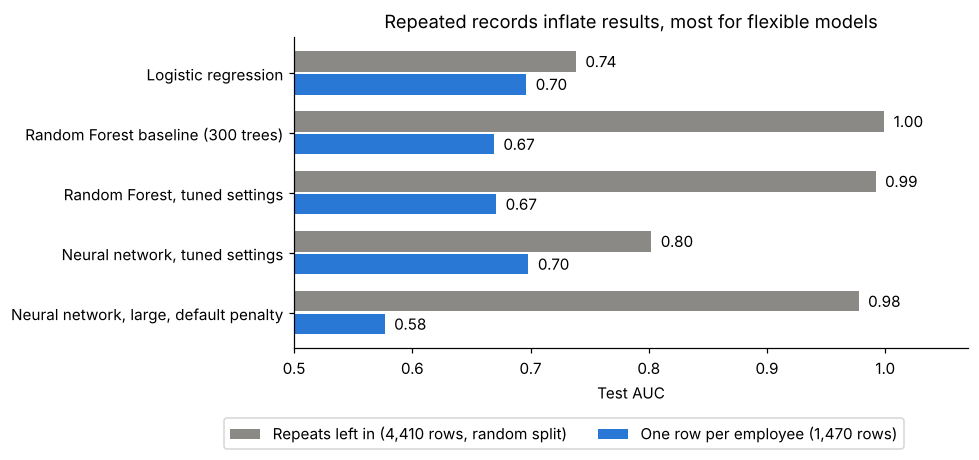

In [44]:
# Picture: the same models, evaluated with and without repeated employees
fig, ax = plt.subplots(figsize=(9, 4.4))
positions = np.arange(len(leak_table))
ax.barh(positions - 0.19, leak_table["naive_test_auc"], height=0.34, color=GRAY,
        label="Repeats left in (4,410 rows, random split)")
ax.barh(positions + 0.19, leak_table["clean_test_auc"], height=0.34, color=BLUE,
        label="One row per employee (1,470 rows)")
for y, (naive_value, clean_value) in enumerate(zip(leak_table["naive_test_auc"], leak_table["clean_test_auc"])):
    ax.text(naive_value + 0.008, y - 0.19, f"{naive_value:.2f}", va="center", fontsize=10)
    ax.text(clean_value + 0.008, y + 0.19, f"{clean_value:.2f}", va="center", fontsize=10)
ax.set_yticks(positions)
ax.set_yticklabels(leak_table.index)
ax.invert_yaxis()
ax.set_xlim(0.5, 1.07)
ax.set_xlabel("Test AUC")
ax.set_title("Repeated records inflate results, most for flexible models")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2, fontsize=10)
plt.tight_layout()
save_fig("leakage_check")
plt.show()

The default-style 300-tree forest caught 95% of leavers at the 50% cutoff when repeats could cross the split. On the clean test set it caught 13% at that cutoff. In the row-level split, 91.4% of test records had a copy in the training data. That explains why the apparent performance with repeats is misleading.

### 7B. How much predictive signal comes from personal characteristics?

We removed age, gender, and marital status and ran the same training cross-validation with the selected settings. This gives an initial view of how much performance changes when those columns are excluded.

In [45]:
# 7B) Cross-validated AUC without age, gender and marital status
sensitive = ["Age", "Male", "Single", "Divorced"]
X_train_reduced = X_train.drop(columns=sensitive)

reduced_rows = []
for name, model, full in [("Random Forest, tuned", best_rf, res_rf), ("Neural network, tuned", make_ann(), res_ann)]:
    reduced = cv_summary(name, model, X=X_train_reduced)
    reduced_rows.append({"model": name, "cv_auc_all_predictors": full["cv_auc"],
                         "cv_auc_without_age_gender_marital": reduced["cv_auc"],
                         "change": reduced["cv_auc"] - full["cv_auc"]})
pd.DataFrame(reduced_rows).set_index("model").round(3)

,cv_auc_all_predictors,cv_auc_without_age_gender_marital,change
model,,,
"Random Forest, tuned",0.753,0.721,-0.032
"Neural network, tuned",0.743,0.712,-0.031


Removing these columns lowered mean validation AUC by about 0.03 for both models. Other variables, such as experience, can still carry related information. Before using a model in a pilot, compare the versions with and without these columns and check which groups are flagged or missed.

## Step 8: Recommendation

We recommend the Random Forest for a small HR pilot. Both tuned models reached about 40% of leavers within the top fifth of the test set. The forest was easier to prepare, had a lower probability error on this test set, and identified 20 leavers in the first 44 names, compared with 15 for the neural network. The difference is based on one split, so we would verify it on a newer employee cohort before expanding the pilot.

Start with supportive check-ins for recent hires and employees with limited time under their current manager. Review travel workload and follow up on low work-environment ratings. Track who was reached and compare retention with a group receiving usual HR support. Include logistic regression as a benchmark in the pilot.

The workbook does not identify voluntary departures or establish when each predictor was recorded relative to departure. Before using the scores as one-year forecasts, confirm that the inputs are available at the time HR would score employees and test on a later cohort.